### Ciencia de Dados 2026.2 - Aula 7
#### Aluno : João Maria de Araujo Nogueira Junior | Matrícula : 20230041950

# Estatística Inferencial
## Objetivos e Motivações
Essa aula ensionou a decidir se uma diferença observada entre dois grupos, refletem um efeito real ou apenas o acaso de uma amostragem. Para isso, formulamos as hipóteses nula e alternativa para aplicarmos ao teste de permutação e o teste t, e interpretar o p-valor, o nível de significância e os erros tipo I e II, assim distinguindo significância estatística de relevância prática.

## 1. Preparando os dados
Primeiramente, vamos importar as bibliotecas, dependencias e o dataset que irei utilizar (**mtcars**)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="darkgrid", palette="pastel", font="Comic Sans MS") 

A base mtcars tem 32 modelos de carro dos EUA (1973-1974), e só sera utilizado nessa aula o mpg (consumo em milhas por galão, quanto maior mais econômico) e am (câmbio: 0 = automático, 1 = manual).

In [2]:
# Carrega a base e cria o rótulo do câmbio
mtcars = pd.read_csv("../data/mtcars/mtcars.csv")
mtcars["transmission"] = np.where(mtcars["am"].eq(0),"automatico","manual")
mtcars.head()

,model,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb,transmission
0,Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4,manual
1,Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4,manual
2,Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1,manual
3,Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1,automatico
4,Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2,automatico


## 2. Diferença Observada

In [3]:
carros_manuais = mtcars[mtcars["transmission"]== "manual"]
carros_automaticos = mtcars[mtcars["transmission"]== "automatico"]

mtcars.groupby("transmission").mpg.agg(["size", "mean", "median", "std"]).round(2)


,size,mean,median,std
transmission,,,,
automatico,19,17.15,17.3,3.83
manual,13,24.39,22.8,6.17


- **Tamanhos desiguais:** são 19 carros automáticos e 13 manuais. como nenhum dos grupos é grande, cada carro influencia bastante a média do seu grupo.
- **Média e mediana diferem um pouco:** nos automáticos os dois valores são quase idênticos (17,15 e 17,3), mas nos manuais a média (24,39) fica acima da mediana (22,8), indicando que alguns carros muito econômicos puxam a média para cima.
- **Manuais variam mais:** o desvio-padrão deles (6,17) é cerca de 60% maior que o dos automáticos (3,83).

In [4]:
mpg_manual = carros_manuais.mpg
mpg_automatic = carros_automaticos.mpg

delta_obs = mpg_manual.mean() - mpg_automatic.mean()

print("Delta Obs (media)= ",round(delta_obs, 2))
print("Delta Obs (mediana)= ",round( mpg_manual.median() - mpg_automatic.median(), 2))

Delta Obs (media)=  7.24
Delta Obs (mediana)=  5.5


Os carros manuais fazem, em média, 7,24 milhas por galão a mais, e a diferença de medianas é menor (5,5 mpg), o que condiz com a assimetria dos manuais, mas nas duas medidas eles aparecem como mais econômicos. O boxplot abaixo mostra a diferença e a dispersão de cada grupo, com cada ponto representando um carro e as linhas tracejadas marcando as médias.

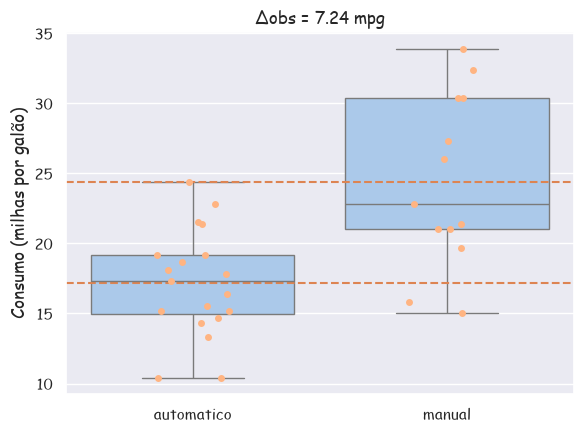

In [5]:
# Boxplot com as observações sobrepostas e as médias de cada grupo
def plot_groups(data, x, y, order, ax, alpha=1, jitter=.15):

    sns.boxplot(data=data, x=x, y=y, order=order, ax=ax,showfliers=False)

    sns.stripplot(data=data, x=x, y=y, order=order, ax=ax, alpha=alpha, jitter=jitter)

fig, ax = plt.subplots(figsize=(6, 4.5))
plot_groups(mtcars, "transmission", "mpg", ["automatico", "manual"], ax)
for mean in [mpg_automatic.mean(), mpg_manual.mean()]:
    ax.axhline(mean, color="#DD8452", linestyle="--")
ax.set(title=f"Δobs = {delta_obs:.2f} mpg", xlabel="",
       ylabel="Consumo (milhas por galão)")
plt.tight_layout()
plt.show()

As caixas do boxplot quase não se sobrepõem, a dos manuais começa perto de onde termina a dos automáticos, e a média dos manuais fica acima de praticamente todos os automáticos, embora ainda haja sobreposição nos extremos. Os manuais parecem mais econômicos, mas isso descreve apenas a amostra e não prova diferença na população, por isso há três motivos para cautela **Natureza estocástica**, **Sensibilidade a valores atípicos**, **Recorte limitado** . A primeira problematica sera abordada no topico a seguir.

## 3. O problema da aleatoriedade

### 3.1 Um pronto-socorro simulado

Abaixo simoulou-se um ano de atendimentos em um pronto-socorro fictício, com todos os dias sorteados da mesma distribuição, de modo que a lua não tem efeito algum. Assim, qualquer diferença entre os grupos é produzida apenas pelo acaso.

In [6]:
# Um ano de atendimentos diários, sem nenhum efeito da lua
rng = np.random.default_rng(2726)

full_moon_days = np.round(np.arange(12) * 29.53 + 14)

er_visits = (
    pd.DataFrame({"day": np.arange(365)})
    .assign(
        visits=rng.poisson(120, size=365),
        full_moon=lambda df: df["day"].isin(full_moon_days),
        moon=lambda df: np.where(df["full_moon"], "Lua cheia", "Demais dias"),
    )
)

Resumo os dois grupos da mesma forma que no mtcars:

In [7]:
# Atendimentos por dia em cada grupo
er_visits.groupby("moon").visits.agg(["size", "mean", "median", "std"]).round(2)

,size,mean,median,std
moon,,,,
Demais dias,353,119.78,119.0,10.94
Lua cheia,12,123.67,121.5,9.36


Na próxima célula, os atendimentos de cada grupo (lua cheia e demais dias) foram separados, como já havia sido feito com manual e automatic, e foi calculado o efeito observado.

In [8]:
vis_demais_dias = er_visits[er_visits["moon"]=="Demais dias"].visits
vis_luas_cheias = er_visits[er_visits["moon"]=="Lua cheia"].visits

moon_obs = vis_luas_cheias.mean() - vis_demais_dias.mean()

print("Delta Obs (media)= ",round(moon_obs, 2))
print("Delta Obs (mediana)= ",round( vis_luas_cheias.median() - vis_demais_dias.median(), 2))

Delta Obs (media)=  3.88
Delta Obs (mediana)=  2.5


aplica-se o bloxplot com o plotgroups da mesma forma que foi feito com o mtcars.

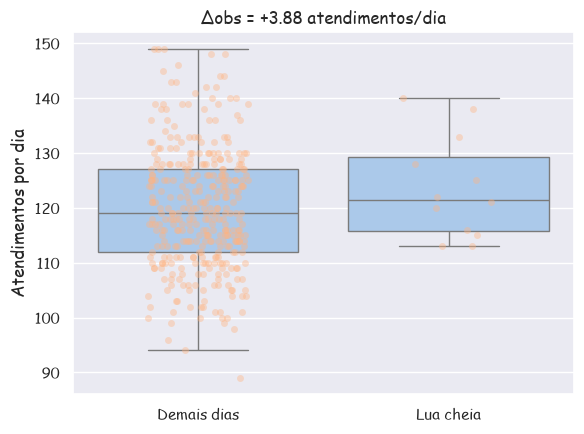

In [9]:
# Atendimentos por grupo
fig, ax = plt.subplots(figsize=(6, 4.5))

plot_groups(
    er_visits, "moon", "visits", ["Demais dias", "Lua cheia"], ax,
    alpha=.4, jitter=.2,
)

ax.set(
    title=f"Δobs = {moon_obs:+.2f} atendimentos/dia",
    xlabel="",
    ylabel="Atendimentos por dia",
)

plt.tight_layout()
plt.show()

Os dias de lua cheia tiveram, em média, cerca de 3,9 atendimentos a mais, o que parece confirmar a crença, apesar de os dados terem sido construídos sem considerar o estado da lua, e o boxplot mostra caixas quase totalmente sobrepostas, ao contrário do mtcars. 
Tendo isso em mente é preciso um procedimento capaz de distinguir os casos sem conhecer a resposta de antemão, considerando não só o tamanho da diferença, mas também quanto ela oscilaria na ausência de efeito.

## 4. Formalizando o acaso

### 4.1 Hipóteses nula e alternativa

Um teste de hipóteses confronta duas proposições sobre a população: 
- hipótese nula (H₀), de que não há efeito e a diferença observada é fruto do acaso.
- hipótese alternativa (H₁), de que existe um efeito real. 

Parte-se de H₀ por ser a única que descreve um cenário preciso, e as alternativas são bilaterais para não escolher o sentido da diferença depois de ver os dados. A lógica é comparavel à de um tribunal, em que H₀ é a presunção de inocência, p-valor ≤ α equivale a “culpado além de dúvida razoável” e não rejeitar H₀ não prova que ela seja verdadeira.

### 4.2 O teste de permutação

Se H₀ for verdadeira, o rótulo “lua cheia” não carrega informação sobre o número de atendimentos, então os rótulos são intercambiáveis. O teste de permutação segue quatro passos: medir o Δobs nos dados reais, embaralhar os rótulos, recalcular o Δ nos dados embaralhados (Δperm) e repetir isso muitas vezes (por exemplo, 10.000) para obter a distribuição nula. No exemplo com seis observações, os valores permanecem nas mesmas posições e só os rótulos trocam de lugar. Há apenas 20 combinações possíveis, mas no pronto-socorro seriam cerca de 9,7 × 10²¹, por isso é sorteada uma amostra grande delas.

Como o procedimento será usado nos dois exemplos anteriores, ele foi colocado em uma função, que a cada repetição embaralha os rótulos e recalcula a diferença de médias. Em seguida, essa função é aplicada aos dados do pronto-socorro.

In [10]:

# Distribuição nula por permutação, aplicada à lua cheia
def permutation_null(values, labels, n_perm=10_000, seed=2026):
    rng = np.random.default_rng(seed)
    null = []
    for _ in range(n_perm):
        shuffled = rng.permutation(labels)
        null.append(values[shuffled].mean() - values[~shuffled].mean())
    return np.array(null)

moon_values = er_visits["visits"].to_numpy()
moon_labels = er_visits["full_moon"].to_numpy()

moon_null = permutation_null(moon_values, moon_labels)

moon_null[:5].round(2)

array([-5.33, -6.46, -2.23, -1.54,  4.49])

Os valores mostram que o acaso pode gerar diferenças positivas ou negativas, até maiores que os 3,9 atendimentos observados. Cada valor de moon_null simula a diferença caso 12 dias aleatórios fossem considerados lua cheia.

A sessão a seguir faz um histograma que reúne as 10.000 diferenças, marcando os limites em $\pm \Delta_{obs}$.

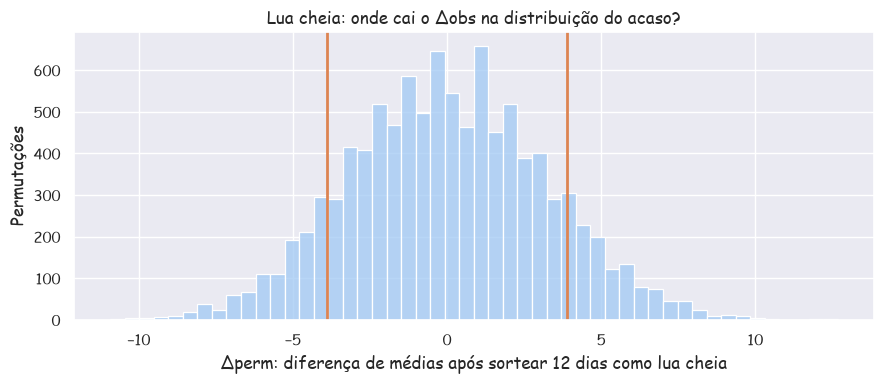

In [11]:
# Distribuição nula da lua cheia e posição do efeito observado
def plot_null(null, obs, title, xlabel):
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.histplot(null, bins=50, color="#A1C9F4", ax=ax)
    for value in [-obs, obs]:
        ax.axvline(value, color="#DD8452", linewidth=2)
    ax.set(title=title, xlabel=xlabel, ylabel="Permutações")
    plt.tight_layout()
    plt.show()

plot_null(
    moon_null,
    moon_obs,
    title="Lua cheia: onde cai o Δobs na distribuição do acaso?",
    xlabel="Δperm: diferença de médias após sortear 12 dias como lua cheia",
)

Neste caso observa-se duas das caracteristicas da distribuição nula :
- Centro em zero, já que nenhum grupo foi favorecida a distribuição se mantem centrada em 0.
- Largura refletindo a oscilação do acaso que ocorre no intervalo de -6 e 6 no caso do dataset artificial.

De todo modo o efeito observado cai numa região povoada da distribuição nula. O código abaixo calcula a proporção de permutações com resultado tão ou mais extremo que o observado:

In [15]:
moon_p = np.mean(np.abs(moon_null) >= abs(moon_obs))

print("p-value: ",moon_p)

p-value:  0.23


### 4.3 P-valor

O p-valor é a probabilidade, supondo $H_0$ verdadeira, de obter um resultado tão extremo ou mais que o observado.

- **Sob $H_0$:** considera-se que não há efeito.
- **Tão ou mais extremo:** considera resultados iguais ou mais distantes de zero ($\geq$).
- **Valor absoluto:** em testes bilaterais, diferenças positivas e negativas contam.

No exemplo, 23% das permutações tiveram diferenças iguais ou maiores que 3,9, indicando que resultados assim não são incomuns mesmo sem efeito real.

O p-valor não deve ser interpretado como a probabilidade de $H_0$ ser verdadeira.

### 4.4 Regra de decisão

Ela utiliza o nível de significância ($\alpha$) para definir o limite que decide se rejeitamos $H_0$. O valor mais comum é 0,05.

- **$p \leq \alpha$:** rejeita-se $H_0$, resultado estatisticamente significativo.
- **$p > \alpha$:** não se rejeita $H_0$, resultado compatível com o acaso. Isso não prova que $H_0$ seja verdadeira.

Com $\alpha = 0{,}05$, aceita-se uma chance de 5% de rejeitar $H_0$ por acaso quando ela é verdadeira.

No exemplo da lua cheia, $p \approx 0{,}23 > 0{,}05$, então não rejeita-se $H_0$.

### 4.5 Permutação no mtcars

Aqui foi repetido o mesmo procedimento de permutação utilizado no dataset sintetico, no dataset do mtcars.

In [17]:
mpg_values = mtcars["mpg"].to_numpy()
mpg_labels = (mtcars["am"] == 1).to_numpy()

mpg_null = permutation_null(mpg_values, mpg_labels)

mpg_p = np.mean(np.abs(mpg_null) >= abs(delta_obs))

print("p-value: ",mpg_p)

p-value:  0.0001


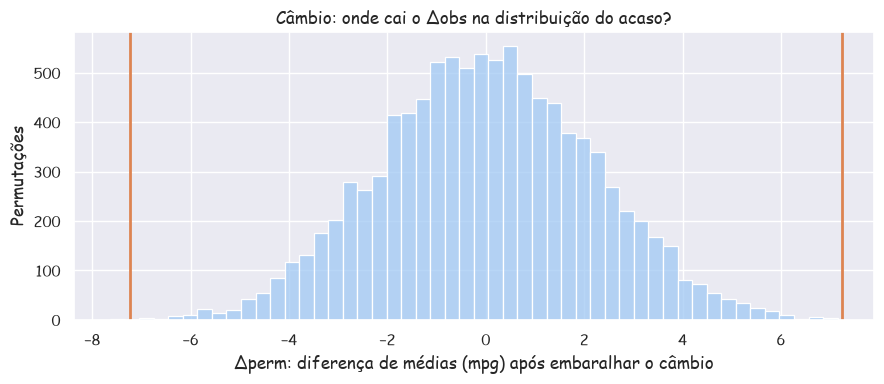

In [19]:
plot_null(mpg_null,delta_obs,title="Câmbio: onde cai o Δobs na distribuição do acaso?",xlabel="Δperm: diferença de médias (mpg) após embaralhar o câmbio")

A distribuição continua centrada em zera, mas agora na escala de mpg. O intervalo de oscilação das diferenças fica entre -4 e 4. Ademais, como o valor p mostrou-se menor que 0.05 , rejeitamos a proposta nula já que uma diferença desse tamanho seria muito rara se o câmbio não importasse.

## 5. O atalho paramétrico